# Interpretable classification of cardiac pathologies (ACDC) with a Tsetlin Machine (Optuna tuning)

This notebook trains a multiclass weighted Tsetlin Machine (TM, `torchtsetlin` 0.6.1) on hand-crafted
cardiac MRI features of the ACDC dataset (5 classes: DCM, HCM, MINF, NOR, RV) and evaluates it on the
official test split.

**Protocol**
1. Training set: ACDC patients 001–100 (20 per class). Test set: patients 101–150 (10 per class).
   The test set is used **once**, only for the final evaluation.
2. Features are binarised with a quantile thermometer encoder fitted on training data only.
3. Hyper-parameters (thermometer bins, number of clauses, threshold T, specificity s) are tuned with
   **Optuna** (TPE sampler, fixed seed, `N_TRIALS` trials, median pruning). The objective of a trial is the
   5-fold stratified CV accuracy on the training set, averaged over several TM seeds per fold and smoothed over
   epochs; the number of epochs is read from the same CV curve.
4. Because the selected CV score is optimistically biased, an **unbiased CV estimate** is obtained with
   **nested CV** (the whole selection procedure is repeated inside every outer fold).
5. Softmax probabilities are obtained from the TM class sums with a temperature fitted on out-of-fold
   class sums of the training set.
6. Final model: retrained on the full training set with the selected hyper-parameters, 10 independent
   seeds. Uncertainty is reported both across seeds and as 95% bootstrap CIs over test patients.

> **Feature provenance — to be stated in the paper.** The CSV files contain features extracted from the
> segmentation masks. State explicitly whether the test-set features were computed from the
> **ground-truth** masks or from automatically **predicted** masks: results on ground-truth masks are an
> upper bound for a fully automatic pipeline.

**Requirements**: see `requirements.txt` (Python ≥ 3.10, `torchtsetlin==0.6.1`, `optuna`, `torch`, `numpy`,
`pandas`, `scikit-learn`, `scipy`, `matplotlib`). Put `features_train.csv` and `features_test.csv` in the
working directory, or set the environment variable `ACDC_TM_DATA` to their folder.

**Reproducibility**: every TM run is seeded explicitly from `SEED`, so results do not depend on the order in
which cells are executed. On GPU, some CUDA kernels are not bit-wise deterministic; the reported results were
produced on the device recorded in `results/results.json`.

## 1. Setup and configuration

In [1]:
import json
import os
import platform
import textwrap
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torchtsetlin as tt
from joblib import Parallel, delayed
from scipy.optimize import minimize_scalar
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             log_loss)
from sklearn.model_selection import StratifiedKFold

# ---- paths ---------------------------------------------------------------------------------------
# Feature set: change the two file names (or set the environment variables) to run another feature set,
# e.g. "features_training.csv" / "features_testing.csv" for the 57-feature set.
ROOT = Path(os.environ.get("ACDC_TM_DATA", Path.cwd()))
TRAIN_CSV = ROOT / os.environ.get("ACDC_TRAIN_CSV", "features_train.csv")
TEST_CSV = ROOT / os.environ.get("ACDC_TEST_CSV", "features_test.csv")
for p in (TRAIN_CSV, TEST_CSV):
    if not p.exists():
        raise FileNotFoundError(f"{p} not found (set ACDC_TM_DATA to the folder with the CSV files)")
OUT = ROOT / os.environ.get("ACDC_OUT", "results")
CL_DIR = OUT / "clauses"
CL_DIR.mkdir(parents=True, exist_ok=True)

# ---- hyper-parameters ----------------------------------------------------------------------------
CLASSES = ["DCM", "HCM", "MINF", "NOR", "RV"]
N_STATES = 100                      # TA states per action, pyTsetlinMachine default (fixed)
EPOCHS = 60                         # maximum number of epochs explored by CV
# Optuna search space (CLAUSES, T, S are set to the selected values in Section 5)
BINS_CHOICES = [2, 3, 5, 8, 10]     # thermometer thresholds per feature
CLAUSES_RANGE = (100, 400, 50)      # clauses per class: low, high, step
T_RANGE = (20, 300)                 # vote threshold T (log scale)
S_RANGE = (2.0, 20.0)               # specificity s (log scale)
N_TRIALS = 30                       # Optuna trials per selection (main and each outer fold)
N_STARTUP = 10                      # random trials before TPE; no pruning before this many trials
FOLDS = 5                           # CV folds (inner and outer)
N_SEL_SEEDS = 2                     # TM seeds averaged per fold during selection
SMOOTH = 2                          # epoch selection on a moving average of +/- SMOOTH epochs
N_CAL_REPEATS = 3                   # repeated CV for temperature calibration
N_RUNS = 10                         # independent seeds of the final model
N_BOOT = 2000                       # bootstrap resamples over test patients
SEED = 42

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_JOBS = 1 if DEVICE == "cuda" else (os.cpu_count() or 1)   # parallel CV curves on CPU; results identical
torch.use_deterministic_algorithms(True, warn_only=True)

# std convention: sample standard deviation (ddof = 1) everywhere
def sd(x):
    x = np.asarray(x, dtype=float)
    return float(x.std(ddof=1)) if x.size > 1 else 0.0

optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONS = {pkg: version(pkg) for pkg in
            ["torchtsetlin", "optuna", "torch", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "joblib"]}
VERSIONS["python"] = platform.python_version()
print("Device:", DEVICE)
print("Versions:", VERSIONS)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
Versions: {'torchtsetlin': '0.6.1', 'optuna': '5.0.0', 'torch': '2.15.0', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'joblib': '1.6.0', 'python': '3.13.18'}


## 2. Data

In [2]:
train_df = pd.read_csv(TRAIN_CSV).rename(columns={"pid": "patient", "label": "group"})
test_df = pd.read_csv(TEST_CSV).rename(columns={"pid": "patient", "label": "group"})

for name, _df in (("train", train_df), ("test", test_df)):
    _df["patient"] = _df["patient"].astype(str).str.extract(r"(\d+)")[0].astype(int)   # "patient117" -> 117
    unknown = sorted(set(_df["group"]) - set(CLASSES))
    if unknown:
        raise ValueError(f"{name} set has unexpected labels {unknown}; expected {CLASSES}")
if set(train_df.patient) & set(test_df.patient):
    raise ValueError("Train and test sets share patient IDs")

meta = ("patient", "group")
feats = [c for c in train_df.columns if c not in meta and train_df[c].notna().any()]
dropped = [c for c in train_df.columns if c not in meta and c not in feats]
missing = [c for c in feats if c not in test_df.columns]
if missing:
    raise ValueError(f"Test set is missing columns: {missing}")

# median imputation with training medians only (no missing values in the provided files)
med = train_df[feats].median()
n_missing = int(train_df[feats].isna().sum().sum() + test_df[feats].isna().sum().sum())
X_train = train_df[feats].fillna(med).to_numpy(np.float64)
X_test = test_df[feats].fillna(med).to_numpy(np.float64)
y_train = train_df["group"].map(CLASSES.index).to_numpy(np.int64)
y_test = test_df["group"].map(CLASSES.index).to_numpy(np.int64)

print(f"Train: {len(y_train)} | Test: {len(y_test)} | {len(feats)} features "
      f"({len(dropped)} all-NaN features dropped, {n_missing} missing values imputed)")
print("Train class counts:", dict(zip(CLASSES, np.bincount(y_train, minlength=5).tolist())))
print("Test  class counts:", dict(zip(CLASSES, np.bincount(y_test, minlength=5).tolist())))

Train: 100 | Test: 50 | 26 features (0 all-NaN features dropped, 0 missing values imputed)
Train class counts: {'DCM': 20, 'HCM': 20, 'MINF': 20, 'NOR': 20, 'RV': 20}
Test  class counts: {'DCM': 10, 'HCM': 10, 'MINF': 10, 'NOR': 10, 'RV': 10}


## 3. Thermometer encoding and Tsetlin Machine helpers

Each feature $x$ is encoded with thresholds $t_1 < \dots < t_B$ at the training-set quantiles
$1/(B+1), \dots, B/(B+1)$; the boolean input $[x > t_b]$ and its negation are the TM literals.

In [3]:
class QuantileThermometer:
    def __init__(self, n_bins):
        self.n_bins = n_bins
        self.thresholds = None

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 2)[1:-1]
        self.thresholds = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        cols = [(X[:, [j]] > thr[None, :]) for j, thr in enumerate(self.thresholds)]
        return np.hstack(cols).astype(np.uint8)

    def literal_names(self, names):
        return [f"{n} > {t:.3g}" for n, thr in zip(names, self.thresholds) for t in thr]


def make_tm(seed, clauses=None, t=None, s=None):
    """New TM; `seed` fixes initialisation and the training-order RNG of this run.
    clauses / t / s default to the selected CLAUSES / T / S (set in Section 5)."""
    clauses = CLAUSES if clauses is None else clauses
    t = T if t is None else t
    s = S if s is None else s
    tt.seed_everything(int(seed))
    # feedback_mode="sequential": examples are learned one at a time (classic TM algorithm)
    return tt.TsetlinMachine(None, len(CLASSES), int(clauses), int(t), float(s), weighted=True,
                             n_states=N_STATES, feedback_mode="sequential").to(DEVICE)


def fit(tm, X, y, epochs):
    """One epoch = one pass over the shuffled training set; calling again continues training."""
    X = torch.tensor(np.asarray(X, dtype=bool), device=DEVICE)
    y = torch.tensor(np.asarray(y, dtype=np.int64), device=DEVICE)
    tm.train()
    for _ in range(epochs):
        perm = torch.randperm(len(y), device=DEVICE)
        tm.update(X[perm], y[perm])
    return tm


def predict(tm, X):
    tm.eval()                                   # eval mode: empty clauses output 0
    return tm.predict(np.asarray(X, dtype=bool)).cpu().numpy()


def train_curve(Xtr, ytr, Xev, yev, seed, clauses, t, s):
    """Validation accuracy after each epoch."""
    tm = make_tm(seed, clauses, t, s)
    accs = []
    for _ in range(EPOCHS):
        fit(tm, Xtr, ytr, 1)
        accs.append(accuracy_score(yev, predict(tm, Xev)))
    return np.array(accs)


def clause_model(tm, n_literals):
    """include[c, j, k]: literal k in clause j of class c (k < n: x_k, k >= n: NOT x_k);
    signed_w[c, j]: clause weight with its polarity (+ votes for class c, - against)."""
    K = len(CLASSES)
    include = tm.included_mask().view(K, tm.n_clauses, 2 * n_literals).cpu().numpy().astype(np.uint8)
    # polarity * weight as computed by the library itself (no assumption on the clause layout)
    signed_w = tm._signed_weights().view(K, tm.n_clauses).cpu().numpy().astype(np.int64)
    return include, signed_w


def clause_fires(include, Xb):
    """(n_patients, n_classes, clauses) bool: clause j of class c fires (empty clauses never fire)."""
    L = np.hstack([Xb, 1 - Xb]).astype(np.int32)
    out = np.zeros((Xb.shape[0], len(CLASSES), include.shape[1]), dtype=bool)
    for c in range(len(CLASSES)):
        violated = (1 - L) @ include[c].T.astype(np.int32)       # included literals that are 0
        out[:, c, :] = (violated == 0) & (include[c].sum(axis=1) > 0)[None, :]
    return out


def class_sums(model, Xb, t):
    include, signed_w = model
    F = clause_fires(include, Xb)
    return np.clip((F * signed_w[None]).sum(axis=2), -t, t).astype(float)


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


# polarity layout check: derived from the library, not assumed
_tm = make_tm(0, 200, 100, 5.0)
_Xb = QuantileThermometer(2).fit(X_train).transform(X_train[:10])
fit(_tm, _Xb, y_train[:10], 1)
_, _sw = clause_model(_tm, _Xb.shape[1])
print("Positive clauses per class:", (_sw > 0).sum(axis=1).tolist(),
      "| negative:", (_sw < 0).sum(axis=1).tolist(), "| zero-weight:", (_sw == 0).sum(axis=1).tolist())
del _tm, _sw

Positive clauses per class: [100, 100, 100, 100, 100] | negative: [100, 100, 100, 100, 100] | zero-weight: [0, 0, 0, 0, 0]


## 4. Hyper-parameter selection procedure (Optuna)

Each Optuna trial proposes (bins, clauses, T, s). For every CV fold, `N_SEL_SEEDS` TMs are trained for
`EPOCHS` epochs and the validation accuracy is recorded after each epoch. The fold curves are averaged and
smoothed with a moving average of ±`SMOOTH` epochs; the trial value is the maximum of the smoothed curve and
its argmax is the number of epochs. After each fold the running score is reported to a median pruner, which
stops unpromising trials (never before `N_STARTUP` complete trials). Trials run one after another with a
seeded TPE sampler, so the search is reproducible. The same function is used for the main model and inside
nested CV.

In [5]:
def smooth(m, k=SMOOTH):
    pad = np.pad(m, k, mode="edge")
    return np.convolve(pad, np.ones(2 * k + 1) / (2 * k + 1), mode="valid")


def _curve_task(X, y, tr, va, n_bins, seed, clauses, t, s):
    torch.set_num_threads(1)
    enc = QuantileThermometer(n_bins).fit(X[tr])
    return train_curve(enc.transform(X[tr]), y[tr], enc.transform(X[va]), y[va], seed, clauses, t, s)


def select_hparams(X, y, seed, verbose=False):
    """Optuna search on (X, y). Returns (params incl. 'epochs', CV curve of the best trial, study)."""
    skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=seed)
    splits = list(skf.split(X, y))

    def objective(trial):
        p = {"n_bins": trial.suggest_categorical("n_bins", BINS_CHOICES),
             "clauses": trial.suggest_int("clauses", CLAUSES_RANGE[0], CLAUSES_RANGE[1], step=CLAUSES_RANGE[2]),
             "T": trial.suggest_int("T", *T_RANGE, log=True),
             "s": trial.suggest_float("s", *S_RANGE, log=True)}
        fold_curves = []
        for f, (tr, va) in enumerate(splits):
            cs = Parallel(n_jobs=min(N_JOBS, N_SEL_SEEDS))(
                delayed(_curve_task)(X, y, tr, va, p["n_bins"], seed * 1000 + 100 * f + k,
                                     p["clauses"], p["T"], p["s"]) for k in range(N_SEL_SEEDS))
            fold_curves.append(np.mean(cs, axis=0))
            trial.report(float(smooth(np.mean(fold_curves, axis=0)).max()), f)
            if f < FOLDS - 1 and trial.should_prune():
                raise optuna.TrialPruned()
        fc = np.array(fold_curves)
        m, sd_ = fc.mean(0), fc.std(0, ddof=1)
        sm = smooth(m)
        e = int(np.argmax(sm))
        trial.set_user_attr("epochs", e + 1)
        trial.set_user_attr("raw_mean", float(m[e]))
        trial.set_user_attr("raw_std", float(sd_[e]))
        trial.set_user_attr("curve", {"mean": m.tolist(), "std": sd_.tolist(), "smooth": sm.tolist()})
        return float(sm[e])

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=N_STARTUP),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=N_STARTUP, n_warmup_steps=1))
    study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
    best = study.best_trial
    params = dict(best.params, epochs=best.user_attrs["epochs"])
    curve = {k: np.array(v) for k, v in best.user_attrs["curve"].items()}
    if verbose:
        n_pruned = sum(t_.state == optuna.trial.TrialState.PRUNED for t_ in study.trials)
        print(f"  {len(study.trials)} trials ({n_pruned} pruned); best trial #{best.number}: "
              f"smoothed CV acc {best.value:.3f}")
    return params, curve, study

## 5. Selection on the full training set

In [7]:
t0 = time.time()
print("Optuna selection on training set (1-100):")
best_params, best_curve, study = select_hparams(X_train, y_train, SEED, verbose=True)
best_bins, best_epoch = best_params["n_bins"], best_params["epochs"]
CLAUSES, T, S = best_params["clauses"], best_params["T"], best_params["s"]
sel_cv = float(best_curve["mean"][best_epoch - 1])
sel_cv_std = float(best_curve["std"][best_epoch - 1])
trials_df = study.trials_dataframe(attrs=("number", "value", "params", "state", "user_attrs"))
trials_df = trials_df.drop(columns=[c for c in trials_df.columns if c.endswith("curve")])
print(trials_df.sort_values("value", ascending=False).head(10).round(3).to_string(index=False))
print(f"\nSelected n_bins={best_bins}, clauses={CLAUSES}, T={T}, s={S:.2f}, epochs={best_epoch} "
      f"(selection CV acc {sel_cv:.3f} ± {sel_cv_std:.3f} — optimistically biased, see nested CV)  "
      f"[{time.time() - t0:.0f}s]")

Optuna selection on training set (1-100):


  30 trials (1 pruned); best trial #25: smoothed CV acc 0.955
 number  value  params_T  params_clauses  params_n_bins  params_s    state  user_attrs_epochs  user_attrs_raw_mean  user_attrs_raw_std
     25  0.955       120             400             10     4.315 COMPLETE               56.0                0.955               0.033
     12  0.940       179             300              8     2.130 COMPLETE               31.0                0.940               0.065
     10  0.937       258             350              8     2.136 COMPLETE               37.0                0.935               0.060
     11  0.937       250             350              8     2.333 COMPLETE               38.0                0.940               0.065
     26  0.936        93             400             10     3.824 COMPLETE               41.0                0.945               0.045
      8  0.935       161             400              8     3.160 COMPLETE               36.0                0.935              

## 6. Nested cross-validation (unbiased CV estimate)

The full Optuna selection of Section 4 is run on each outer training split; a TM with the selected
hyper-parameters is then trained on that split and evaluated on the held-out outer fold.

In [8]:
t0 = time.time()
outer = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED + 1)
OUTER_SPLITS = list(outer.split(X_train, y_train))
N_OUTER_RUNS = 3
nested = []
for f, (tr, va) in enumerate(OUTER_SPLITS):
    p, _, _ = select_hparams(X_train[tr], y_train[tr], SEED + 10 + f)
    enc_f = QuantileThermometer(p["n_bins"]).fit(X_train[tr])
    accs = []
    for r in range(N_OUTER_RUNS):
        tm_f = fit(make_tm(SEED * 7 + 31 * f + r, p["clauses"], p["T"], p["s"]),
                   enc_f.transform(X_train[tr]), y_train[tr], p["epochs"])
        accs.append(accuracy_score(y_train[va], predict(tm_f, enc_f.transform(X_train[va]))))
    nested.append({"fold": f + 1, **p, "accuracy": float(np.mean(accs))})
    print(f"outer fold {f + 1}: selected n_bins={p['n_bins']}, clauses={p['clauses']}, T={p['T']}, "
          f"s={p['s']:.2f}, epochs={p['epochs']} -> held-out acc {np.mean(accs):.3f}")
nested_df = pd.DataFrame(nested)
NESTED_ACC, NESTED_STD = float(nested_df.accuracy.mean()), sd(nested_df.accuracy)
print(f"\nNested CV accuracy: {NESTED_ACC:.3f} ± {NESTED_STD:.3f} (mean ± SD over {FOLDS} outer folds) "
      f"[{time.time() - t0:.0f}s]")

outer fold 1: selected n_bins=5, clauses=100, T=86, s=2.01, epochs=36 -> held-out acc 0.950


outer fold 2: selected n_bins=10, clauses=150, T=83, s=2.92, epochs=24 -> held-out acc 0.833


outer fold 3: selected n_bins=5, clauses=250, T=245, s=2.51, epochs=60 -> held-out acc 0.967


outer fold 4: selected n_bins=3, clauses=150, T=206, s=2.20, epochs=55 -> held-out acc 0.950


outer fold 5: selected n_bins=5, clauses=350, T=204, s=2.80, epochs=52 -> held-out acc 0.917

Nested CV accuracy: 0.923 ± 0.053 (mean ± SD over 5 outer folds) [446s]


## 7. Temperature calibration on out-of-fold class sums

Class sums are converted to probabilities with $p = \mathrm{softmax}(s/\tau)$. $\tau$ minimises the
negative log-likelihood of out-of-fold class sums (repeated 5-fold CV on the training set).

In [9]:
oof_sums, oof_y = [], []
for r in range(N_CAL_REPEATS):
    skf_r = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED + 100 + r)
    for f, (tr, va) in enumerate(skf_r.split(X_train, y_train)):
        enc_f = QuantileThermometer(best_bins).fit(X_train[tr])
        Xtr_f, Xva_f = enc_f.transform(X_train[tr]), enc_f.transform(X_train[va])
        tm_f = fit(make_tm(SEED * 13 + 10 * r + f), Xtr_f, y_train[tr], best_epoch)
        oof_sums.append(class_sums(clause_model(tm_f, Xtr_f.shape[1]), Xva_f, T))
        oof_y.append(y_train[va])
oof_sums, oof_y = np.vstack(oof_sums), np.concatenate(oof_y)


def nll(log_tau, sums, y):
    p = softmax(sums / np.exp(log_tau))
    return -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))


res = minimize_scalar(nll, bounds=(np.log(0.1), np.log(10 * T)), args=(oof_sums, oof_y), method="bounded")
TAU = float(np.exp(res.x))
OOF_ACC = float(np.mean(oof_sums.argmax(1) == oof_y))
print(f"Fitted temperature tau = {TAU:.2f}  (OOF NLL {res.fun:.3f}, OOF accuracy {OOF_ACC:.3f})")

Fitted temperature tau = 28.40  (OOF NLL 0.261, OOF accuracy 0.903)


## 8. Final model: test-set evaluation (patients 101–150)

* **Across seeds**: mean ± SD over `N_RUNS` independently seeded TMs (captures TM stochasticity only).
* **Bootstrap 95% CI**: patients are resampled with replacement (`N_BOOT` times); for each resample the
  metric is averaged over the seeds. This captures the sampling uncertainty of a 50-patient test set.
* Brier score: multiclass form $\frac1N\sum_i\sum_k (p_{ik}-y_{ik})^2$, range [0, 2].
* ECE: 10 equal-width confidence bins; with 50 patients it is a noisy estimate.

In [10]:
def ece_score(probs, y, n_bins=10):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e


def brier(probs, y):
    return np.mean(np.sum((probs - np.eye(len(CLASSES))[y]) ** 2, axis=1))


def bootstrap_ci(preds_list, y, n_boot=N_BOOT, seed=SEED):
    """95% percentile CI of seed-averaged accuracy and macro-F1, resampling patients."""
    rng = np.random.default_rng(seed)
    P = np.asarray(preds_list)
    accs, f1s = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        accs.append(np.mean([accuracy_score(y[idx], p[idx]) for p in P]))
        f1s.append(np.mean([f1_score(y[idx], p[idx], average="macro", labels=range(len(CLASSES)),
                                     zero_division=0) for p in P]))
    return {"accuracy": np.percentile(accs, [2.5, 97.5]).tolist(),
            "macro_f1": np.percentile(f1s, [2.5, 97.5]).tolist(),
            "_acc_samples": np.array(accs)}


enc = QuantileThermometer(best_bins).fit(X_train)
Xtr_b, Xte_b = enc.transform(X_train), enc.transform(X_test)
n_lit = Xtr_b.shape[1]

runs, all_probs, all_preds, models = [], [], [], []
for r in range(N_RUNS):
    tm = fit(make_tm(SEED * 1000 + 1000 + r), Xtr_b, y_train, best_epoch)
    y_pred = predict(tm, Xte_b)
    sums = class_sums(clause_model(tm, n_lit), Xte_b, T)
    probs = softmax(sums / TAU)
    agree = np.mean(sums.argmax(1) == y_pred)          # sanity check of the class-sum reconstruction
    runs.append({"run": r + 1, "accuracy": accuracy_score(y_test, y_pred),
                 "macro_f1": f1_score(y_test, y_pred, average="macro"),
                 "ece": ece_score(probs, y_test), "brier": brier(probs, y_test),
                 "nll": log_loss(y_test, probs, labels=range(len(CLASSES))),
                 "argmax_agreement": agree})
    all_probs.append(probs); all_preds.append(y_pred); models.append(tm)
    print(f"run {r + 1:>2}: acc {runs[-1]['accuracy']:.3f} | macro-F1 {runs[-1]['macro_f1']:.3f} | "
          f"ECE {runs[-1]['ece']:.3f} | class-sum/predict agreement {agree:.2f}")

runs_df = pd.DataFrame(runs)
summary = runs_df.drop(columns="run").agg(["mean", sd]).T.rename(columns={"sd": "std"})
TM_CI = bootstrap_ci(all_preds, y_test)

print(f"\nTEST accuracy: {runs_df.accuracy.mean():.3f} ± {sd(runs_df.accuracy):.3f} across {N_RUNS} seeds "
      f"(min {runs_df.accuracy.min():.3f}, max {runs_df.accuracy.max():.3f}); "
      f"95% bootstrap CI [{TM_CI['accuracy'][0]:.3f}, {TM_CI['accuracy'][1]:.3f}]")
print(f"TEST macro-F1: {runs_df.macro_f1.mean():.3f}; 95% bootstrap CI "
      f"[{TM_CI['macro_f1'][0]:.3f}, {TM_CI['macro_f1'][1]:.3f}]")
print(f"\nCV estimates on the training set: selection {sel_cv:.3f} (biased) | "
      f"OOF (calibration folds) {OOF_ACC:.3f} | nested {NESTED_ACC:.3f} ± {NESTED_STD:.3f}\n")
print(summary.round(3))

recalls = np.array([[np.mean(p[y_test == c] == c) for c in range(len(CLASSES))] for p in all_preds])
print("\nPer-class recall (mean ± SD across seeds):")
for c, name in enumerate(CLASSES):
    print(f"  {name:<5} {recalls[:, c].mean():.3f} ± {sd(recalls[:, c]):.3f}")

cm_mean = np.mean([confusion_matrix(y_test, p, labels=range(5)) for p in all_preds], axis=0)
print("\nMean confusion matrix over seeds (rows = true, cols = predicted):\n", cm_mean.round(1))
err_rate = np.mean([p != y_test for p in all_preds], axis=0)
wrong = [(int(pid), CLASSES[t], f"{e:.0%}") for pid, t, e in zip(test_df["patient"], y_test, err_rate) if e > 0]
print("Misclassified patients (true class, % of seeds wrong):", wrong)

# representative model: the seed whose accuracy is closest to the mean (first one in case of ties)
rep = int(np.argmin(np.abs(runs_df.accuracy - runs_df.accuracy.mean())))
tm = models[rep]
print(f"\nRepresentative model: run {rep + 1} (accuracy closest to the mean; first in case of ties)")
print(classification_report(y_test, all_preds[rep], labels=range(5), target_names=CLASSES,
                            digits=3, zero_division=0))

run  1: acc 0.860 | macro-F1 0.857 | ECE 0.081 | class-sum/predict agreement 1.00


run  2: acc 0.880 | macro-F1 0.877 | ECE 0.089 | class-sum/predict agreement 1.00


run  3: acc 0.860 | macro-F1 0.857 | ECE 0.122 | class-sum/predict agreement 1.00


run  4: acc 0.880 | macro-F1 0.881 | ECE 0.086 | class-sum/predict agreement 1.00


run  5: acc 0.860 | macro-F1 0.860 | ECE 0.127 | class-sum/predict agreement 1.00


run  6: acc 0.840 | macro-F1 0.833 | ECE 0.100 | class-sum/predict agreement 1.00


run  7: acc 0.840 | macro-F1 0.837 | ECE 0.117 | class-sum/predict agreement 1.00


run  8: acc 0.820 | macro-F1 0.818 | ECE 0.156 | class-sum/predict agreement 1.00


run  9: acc 0.860 | macro-F1 0.857 | ECE 0.106 | class-sum/predict agreement 1.00


run 10: acc 0.840 | macro-F1 0.836 | ECE 0.085 | class-sum/predict agreement 1.00



TEST accuracy: 0.854 ± 0.019 across 10 seeds (min 0.820, max 0.880); 95% bootstrap CI [0.766, 0.932]
TEST macro-F1: 0.851; 95% bootstrap CI [0.749, 0.931]

CV estimates on the training set: selection 0.955 (biased) | OOF (calibration folds) 0.903 | nested 0.923 ± 0.053

                   mean    std
accuracy          0.854  0.019
macro_f1          0.851  0.020
ece               0.107  0.024
brier             0.228  0.022
nll               0.564  0.054
argmax_agreement  1.000  0.000

Per-class recall (mean ± SD across seeds):
  DCM   0.840 ± 0.052
  HCM   0.980 ± 0.042
  MINF  0.750 ± 0.053
  NOR   0.730 ± 0.082
  RV    0.970 ± 0.048

Mean confusion matrix over seeds (rows = true, cols = predicted):
 [[8.4 0.  1.6 0.  0. ]
 [0.  9.8 0.  0.2 0. ]
 [2.2 0.3 7.5 0.  0. ]
 [0.  1.5 0.1 7.3 1.1]
 [0.  0.3 0.  0.  9.7]]
Misclassified patients (true class, % of seeds wrong): [(101, 'DCM', '50%'), (107, 'NOR', '90%'), (110, 'NOR', '70%'), (122, 'DCM', '10%'), (123, 'NOR', '90%'), (125, 'NOR',

## 9. Figures: CV selection, test confusion matrix, calibration

Reliability diagrams pool the 10 seeds × 50 test patients; the 500 points are not independent (same 50
patients), so the bin counts overstate the evidence.

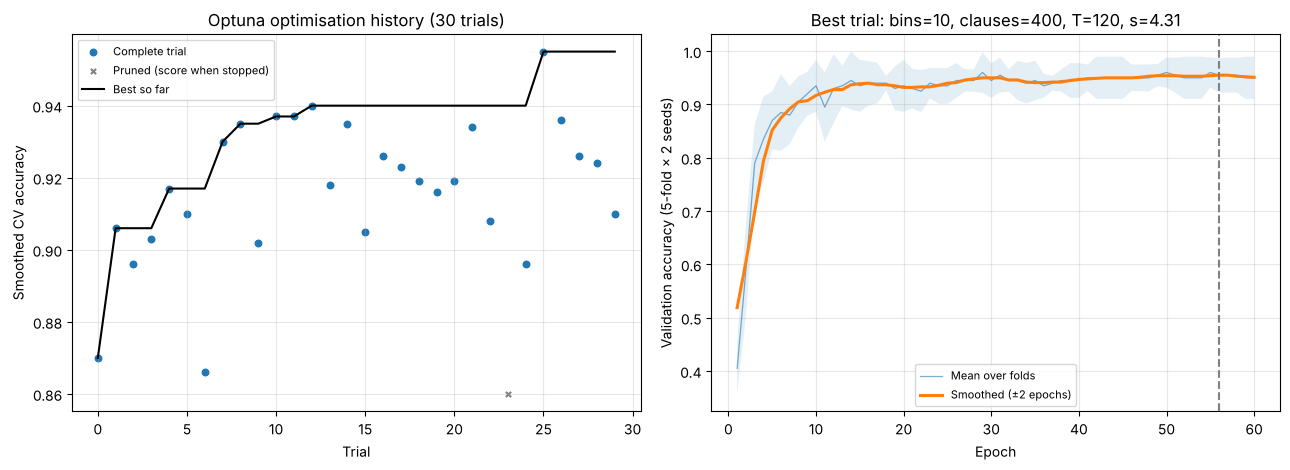

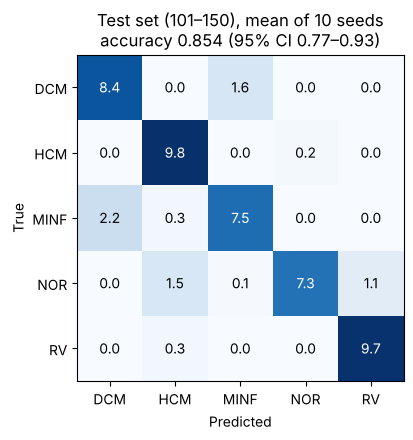

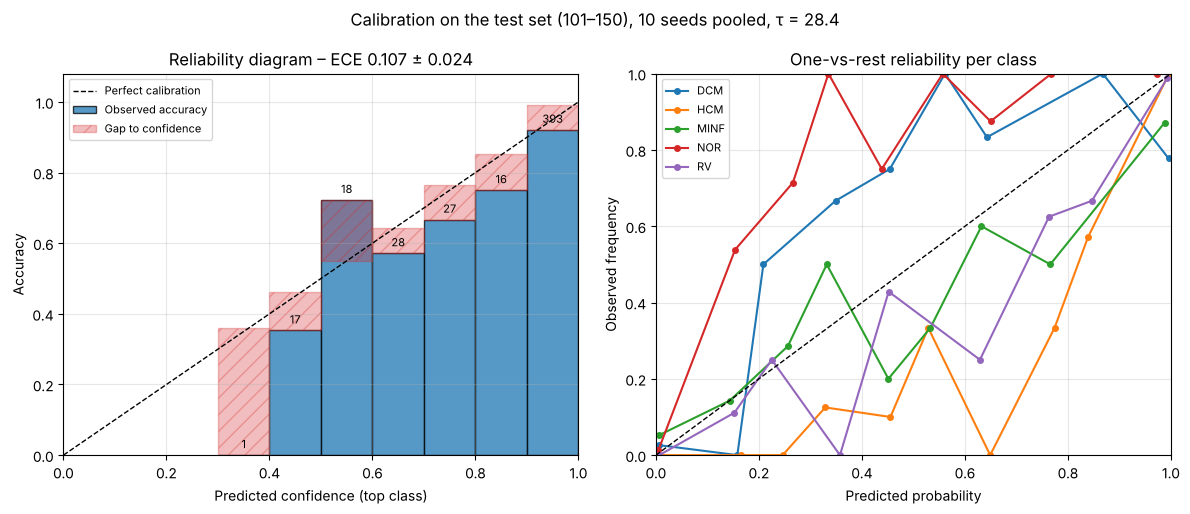

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
done = trials_df[trials_df.state == "COMPLETE"]
pruned = trials_df[trials_df.state == "PRUNED"]
ax.scatter(done.number, done.value, s=22, label="Complete trial")
ax.scatter(pruned.number, pruned.value, s=14, marker="x", color="gray", label="Pruned (score when stopped)")
ax.plot(done.number, done.value.cummax(), color="k", lw=1.5, label="Best so far")
ax.set(xlabel="Trial", ylabel="Smoothed CV accuracy", title=f"Optuna optimisation history ({N_TRIALS} trials)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1]
ep = np.arange(1, EPOCHS + 1)
ax.plot(ep, best_curve["mean"], lw=0.9, alpha=0.6, label="Mean over folds")
ax.fill_between(ep, best_curve["mean"] - best_curve["std"], best_curve["mean"] + best_curve["std"], alpha=0.12)
ax.plot(ep, best_curve["smooth"], lw=2.2, label=f"Smoothed (±{SMOOTH} epochs)")
ax.axvline(best_epoch, ls="--", c="gray")
ax.set(xlabel="Epoch", ylabel=f"Validation accuracy ({FOLDS}-fold × {N_SEL_SEEDS} seeds)",
       title=f"Best trial: bins={best_bins}, clauses={CLAUSES}, T={T}, s={S:.2f}")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "cv_curves.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm_mean, cmap="Blues")
ax.set_xticks(range(5), CLASSES); ax.set_yticks(range(5), CLASSES)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm_mean[i, j]:.1f}", ha="center", va="center",
                color="white" if cm_mean[i, j] > cm_mean.max() / 2 else "black")
ax.set(xlabel="Predicted", ylabel="True",
       title=f"Test set (101–150), mean of {N_RUNS} seeds\naccuracy {runs_df.accuracy.mean():.3f} "
             f"(95% CI {TM_CI['accuracy'][0]:.2f}–{TM_CI['accuracy'][1]:.2f})")
fig.tight_layout(); fig.savefig(OUT / "test_confusion.png", dpi=200); plt.show()

P = np.vstack(all_probs)
Y = np.tile(y_test, N_RUNS)
conf, pred = P.max(1), P.argmax(1)
N_BINS = 10
edges = np.linspace(0, 1, N_BINS + 1)
centers = (edges[:-1] + edges[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
ax = axes[0]
acc_bin, conf_bin, n_bin = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    n_bin.append(int(m.sum()))
    acc_bin.append((pred[m] == Y[m]).mean() if m.any() else np.nan)
    conf_bin.append(conf[m].mean() if m.any() else np.nan)
acc_bin, conf_bin = np.array(acc_bin), np.array(conf_bin)
ok = ~np.isnan(acc_bin)
ax.bar(centers[ok], acc_bin[ok], width=1 / N_BINS, edgecolor="k", alpha=0.75, label="Observed accuracy")
ax.bar(centers[ok], (conf_bin - acc_bin)[ok], bottom=acc_bin[ok], width=1 / N_BINS,
       color="tab:red", alpha=0.3, edgecolor="tab:red", hatch="//", label="Gap to confidence")
for x, a, n in zip(centers[ok], acc_bin[ok], np.array(n_bin)[ok]):
    ax.text(x, a + 0.02, str(n), ha="center", fontsize=8)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set(xlim=(0, 1), ylim=(0, 1.08), xlabel="Predicted confidence (top class)", ylabel="Accuracy",
       title=f"Reliability diagram – ECE {runs_df.ece.mean():.3f} ± {sd(runs_df.ece):.3f}")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
ax = axes[1]
for c, name in enumerate(CLASSES):
    pc, yc = P[:, c], (Y == c)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (pc > lo) & (pc <= hi) if lo > 0 else (pc >= lo) & (pc <= hi)
        if m.sum() >= 3:
            xs.append(pc[m].mean()); ys.append(yc[m].mean())
    ax.plot(xs, ys, "o-", ms=4, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Predicted probability", ylabel="Observed frequency",
       title="One-vs-rest reliability per class")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle(f"Calibration on the test set (101–150), {N_RUNS} seeds pooled, τ = {TAU:.1f}")
fig.tight_layout(); fig.savefig(OUT / "calibration_plot.png", dpi=200, bbox_inches="tight"); plt.show()

## 10. Interpretability: clauses of the representative model

Thermometer literals of the same feature are merged into one interval ($a < x \le b$), so rule length is
reported as the number of **conditions** (features involved) rather than raw literals. Clauses whose merged
interval is empty ($a \ge b$) can never fire and are flagged. Precision = fraction of patients on which a
positive clause fires that belong to its class; recall = fraction of the class on which it fires.

In [12]:
lit_names = enc.literal_names(feats)
lit_feat = np.concatenate([[i] * len(t) for i, t in enumerate(enc.thresholds)])   # literal -> feature
lit_thr = np.concatenate(enc.thresholds)                                           # literal -> threshold
include, signed_w = clause_model(tm, n_lit)
POSITIVE = signed_w > 0                                    # (classes, clauses), derived from the library
colors = dict(zip(CLASSES, plt.cm.tab10.colors))


def simplify(inc):
    """Merge the thermometer literals of each feature into one interval lo < x <= hi.
    Returns (conditions, has_empty_interval)."""
    lo, hi = {}, {}
    for k in inc:
        f, t = lit_feat[k % n_lit], lit_thr[k % n_lit]
        if k < n_lit:
            lo[f] = max(lo.get(f, -np.inf), t)             # x > t
        else:
            hi[f] = min(hi.get(f, np.inf), t)              # NOT(x > t) -> x <= t
    conds, empty = [], False
    for f in sorted(set(lo) | set(hi), key=lambda f: feats[f]):
        a, b = lo.get(f, -np.inf), hi.get(f, np.inf)
        if np.isfinite(a) and np.isfinite(b):
            if a >= b:
                empty = True
                conds.append(f"[EMPTY] {a:.3g} < {feats[f]} ≤ {b:.3g}")
            else:
                conds.append(f"{a:.3g} < {feats[f]} ≤ {b:.3g}")
        elif np.isfinite(a):
            conds.append(f"{feats[f]} > {a:.3g}")
        else:
            conds.append(f"{feats[f]} ≤ {b:.3g}")
    return conds, empty


F_tr, F_te = clause_fires(include, Xtr_b), clause_fires(include, Xte_b)
rows = []
for c, cname in enumerate(CLASSES):
    for j in range(include.shape[1]):
        inc = np.flatnonzero(include[c, j])
        if inc.size == 0:
            continue
        pol = "+" if POSITIVE[c, j] else "-"
        conds, empty = simplify(inc)
        tr, te = F_tr[:, c, j], F_te[:, c, j]
        tgt_tr = (y_train == c) if pol == "+" else (y_train != c)
        tgt_te = (y_test == c) if pol == "+" else (y_test != c)
        rows.append({
            "class": cname, "clause": j, "polarity": pol, "weight": int(abs(signed_w[c, j])),
            "n_literals": int(inc.size), "n_conditions": len(conds), "empty_interval": empty,
            "coverage_train": tr.mean(), "precision_train": tgt_tr[tr].mean() if tr.any() else np.nan,
            "recall_train": tr[tgt_tr].mean(),
            "coverage_test": te.mean(), "precision_test": tgt_te[te].mean() if te.any() else np.nan,
            "recall_test": te[tgt_te].mean(),
            "rule": " AND ".join(conds),
            "rule_literals": " AND ".join(lit_names[k] if k < n_lit else f"NOT({lit_names[k - n_lit]})"
                                          for k in inc),
        })
clauses_df = (pd.DataFrame(rows).sort_values(["class", "polarity", "weight"], ascending=[True, True, False])
              .reset_index(drop=True))
clauses_df.to_csv(CL_DIR / "clauses_all.csv", index=False)
pos = clauses_df[clauses_df.polarity == "+"]

print(f"Non-empty clauses: {len(clauses_df)} | with an empty interval (never fire): "
      f"{int(clauses_df.empty_interval.sum())}")
length_stats = (clauses_df.groupby("polarity")[["n_literals", "n_conditions"]]
                .median().rename(index={"+": "positive", "-": "negative"}))
print("Median clause length (literals vs merged conditions):\n", length_stats)

TOP_K = 10
with open(CL_DIR / "clauses_rules.txt", "w", encoding="utf-8") as f:
    f.write(f"torchtsetlin - top {TOP_K} positive clauses (rules) per class, representative run {rep + 1}\n")
    f.write("prec = fraction of patients where the rule fires that belong to the class; "
            "rec = fraction of the class where the rule fires\n\n")
    for cname in CLASSES:
        f.write(f"=== {cname} ===\n")
        for _, r in pos[pos["class"] == cname].head(TOP_K).iterrows():
            f.write(f"clause #{r.clause}  weight={r.weight}  conditions={r.n_conditions}  "
                    f"train prec={r.precision_train:.2f} rec={r.recall_train:.2f} | "
                    f"test prec={r.precision_test:.2f} rec={r.recall_test:.2f}\n")
            f.write("  IF " + "\n     AND ".join(r.rule.split(" AND ")) + f"\n  THEN {cname}\n\n")

# top-3 rules per class (merged conditions), also stored in results.json
top_rules = {c: [{"clause": int(r.clause), "weight": int(r.weight), "n_conditions": int(r.n_conditions),
                  "precision_train": float(r.precision_train), "recall_train": float(r.recall_train),
                  "precision_test": None if np.isnan(r.precision_test) else float(r.precision_test),
                  "recall_test": float(r.recall_test), "rule": r.rule}
                 for _, r in pos[pos["class"] == c].head(3).iterrows()] for c in CLASSES}
for c, rs in top_rules.items():
    print(f"\n{c}:")
    for r in rs:
        print(f"  w={r['weight']:>3}, {r['n_conditions']} conditions, train prec {r['precision_train']:.2f} "
              f"rec {r['recall_train']:.2f}: IF {r['rule']}")

Non-empty clauses: 1970 | with an empty interval (never fire): 5
Median clause length (literals vs merged conditions):
           n_literals  n_conditions
polarity                          
positive         9.0           8.0
negative         3.0           3.0

DCM:
  w= 12, 26 conditions, train prec 1.00 rec 0.05: IF 1.56 < BSA ≤ 1.96 AND Height ≤ 180 AND 121 < LV_EDV ≤ 291 AND 98.9 < LV_EDV_idx ≤ 161 AND 0.15 < LV_EF ≤ 0.297 AND LV_ESV > 120 AND 65.9 < LV_ESV_idx ≤ 128 AND MYO_LV_ED_ratio ≤ 0.614 AND 0.714 < MYO_LV_ES_ratio ≤ 1.05 AND 112 < MYO_mass_ED ≤ 155 AND 67.3 < MYO_mass_idx ≤ 78.8 AND 73.2 < MYO_vol_ES ≤ 141 AND 104 < RV_EDV ≤ 161 AND 56.4 < RV_EDV_idx ≤ 96.5 AND 0.467 < RV_EF ≤ 0.634 AND 59.5 < RV_ESV ≤ 84.7 AND 18.2 < RV_ESV_idx ≤ 46.4 AND RV_LV_EDV_ratio ≤ 0.755 AND RV_LV_ESV_ratio ≤ 1.1 AND Thick_max_ED ≤ 11.1 AND Thick_max_ES ≤ 19.6 AND 7.03 < Thick_mean_ED ≤ 7.86 AND 9.42 < Thick_mean_ES ≤ 12.5 AND Thick_std_ED ≤ 0.889 AND 0.959 < Thick_std_ES ≤ 4.02 AND 54 < Weight ≤ 76

### Clause figures

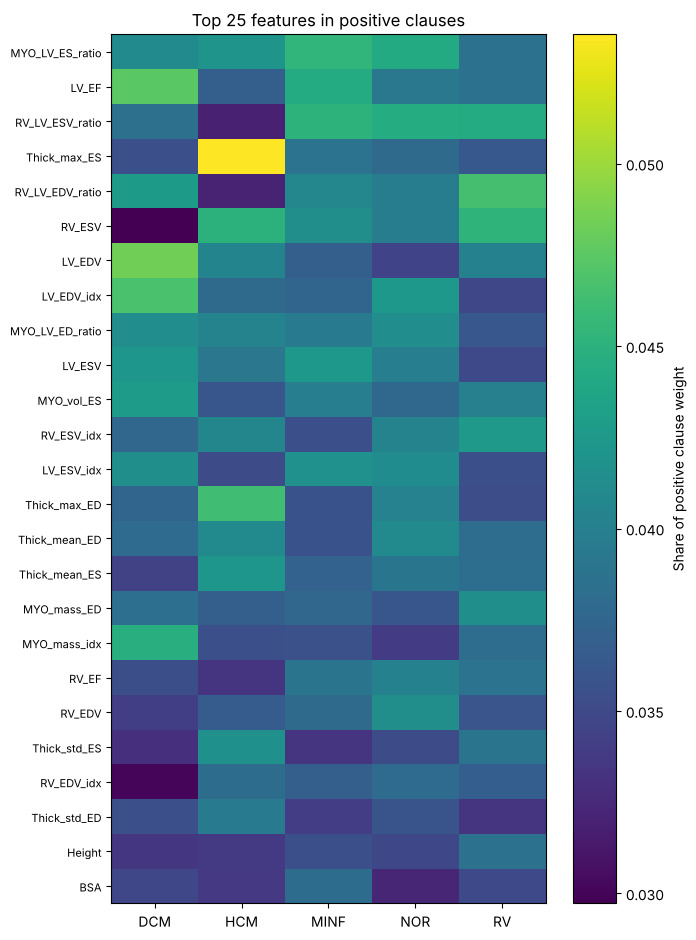

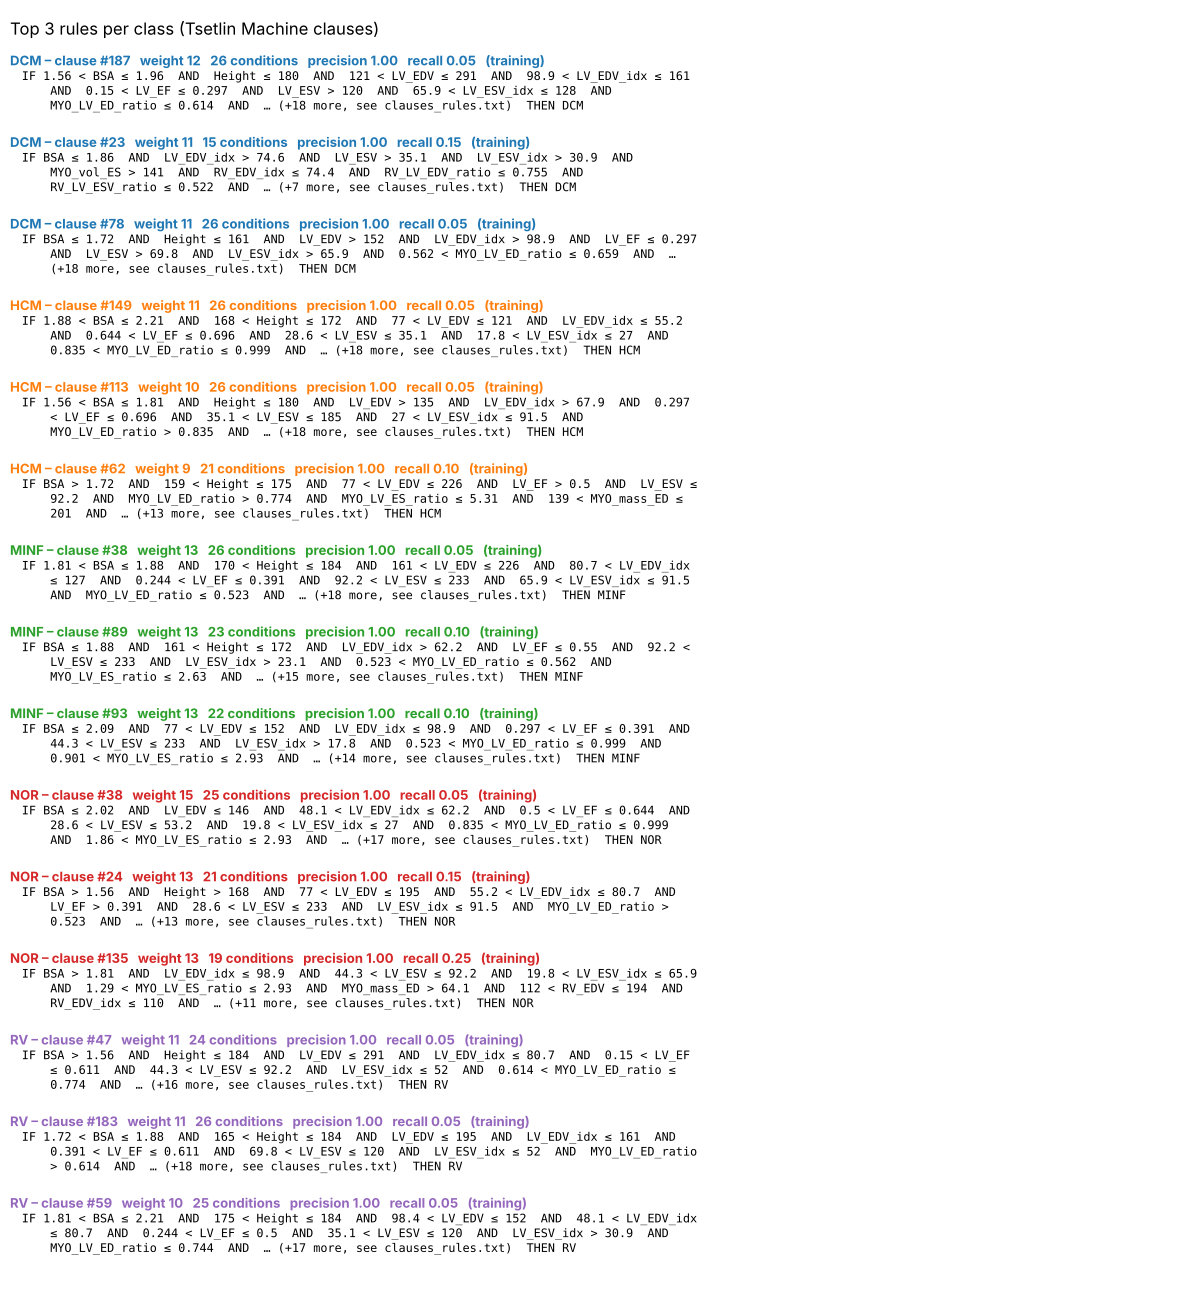

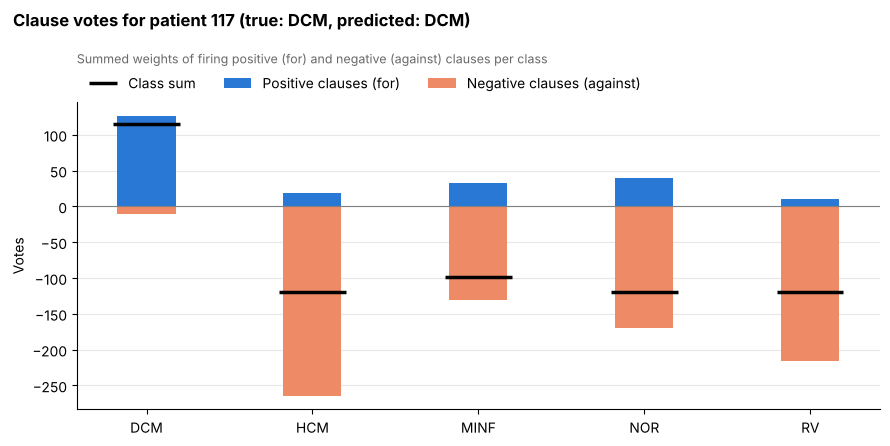

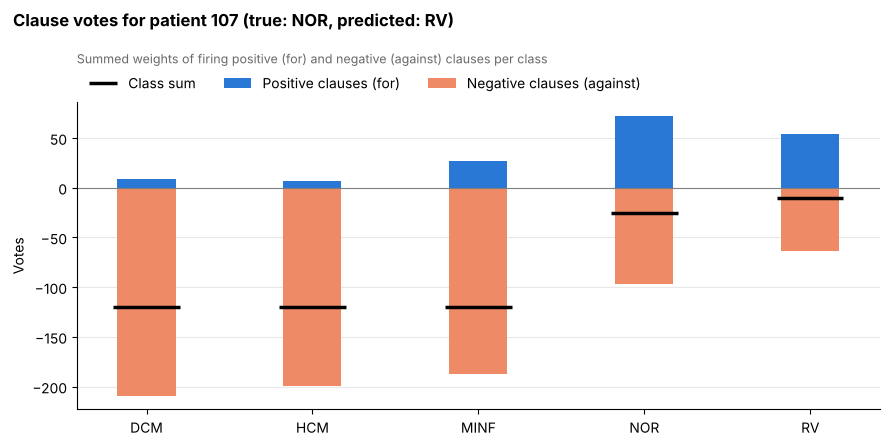

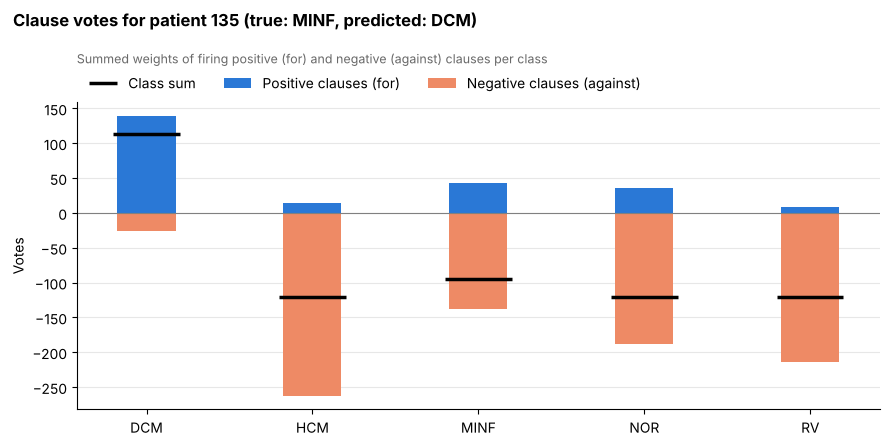

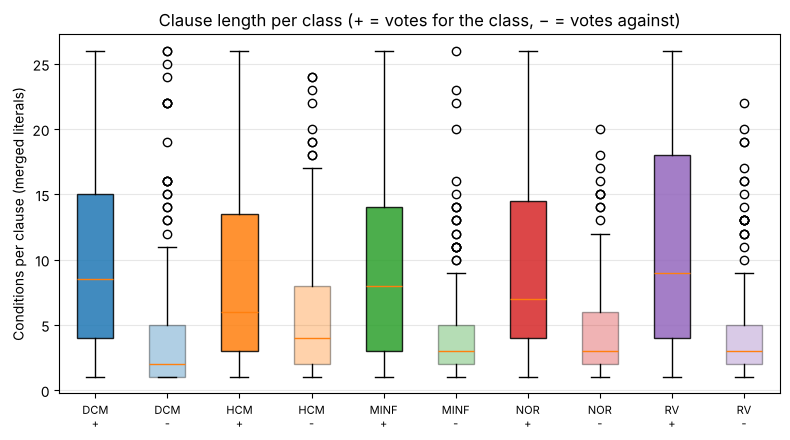

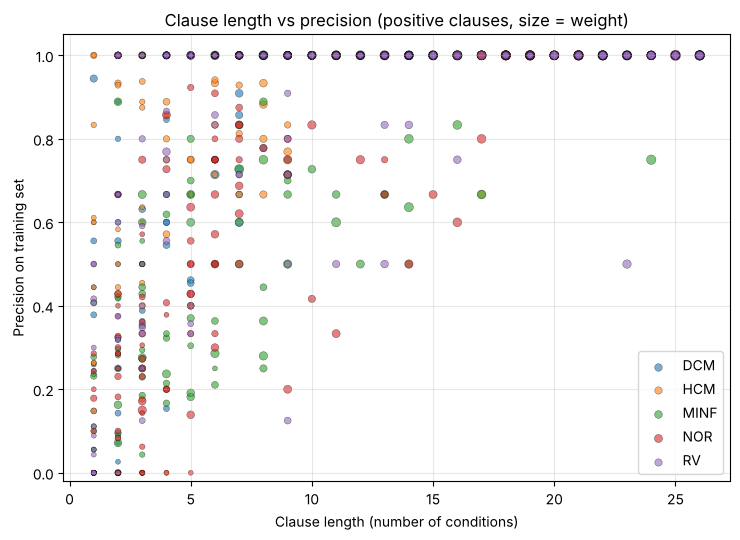

In [13]:
# ---- 1. feature importance per class (share of positive clause weight) -----------------------------
imp = np.zeros((len(feats), len(CLASSES)))
for c in range(len(CLASSES)):
    for j in np.flatnonzero(POSITIVE[c]):
        inc = np.flatnonzero(include[c, j])
        for fi in set(lit_feat[inc % n_lit]):
            imp[fi, c] += abs(signed_w[c, j])
imp_norm = imp / np.maximum(imp.sum(axis=0, keepdims=True), 1e-12)
pd.DataFrame(imp_norm, index=feats, columns=CLASSES).to_csv(CL_DIR / "feature_importance_clauses.csv")
N_TOP_F = min(25, len(feats))
order = np.argsort(-imp_norm.sum(axis=1))[:N_TOP_F]
fig, ax = plt.subplots(figsize=(7, 0.32 * N_TOP_F + 1.5))
im = ax.imshow(imp_norm[order], cmap="viridis", aspect="auto")
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(N_TOP_F), [feats[i] for i in order], fontsize=8)
fig.colorbar(im, ax=ax, label="Share of positive clause weight")
ax.set_title(f"Top {N_TOP_F} features in positive clauses")
fig.tight_layout(); fig.savefig(CL_DIR / "1_heatmap_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- 2. clauses as rules --------------------------------------------------------------------------
RULES_SHOWN, MAX_CONDS, WRAP = 3, 8, 95
blocks = []
for cname in CLASSES:
    for _, r in pos[pos["class"] == cname].head(RULES_SHOWN).iterrows():
        conds = r.rule.split(" AND ")
        shown = conds[:MAX_CONDS] + ([f"… (+{len(conds) - MAX_CONDS} more, see clauses_rules.txt)"]
                                     if len(conds) > MAX_CONDS else [])
        body = textwrap.fill("IF " + "  AND  ".join(shown) + f"  THEN {cname}", WRAP, subsequent_indent="    ")
        head = (f"{cname} – clause #{r.clause}   weight {r.weight}   {r.n_conditions} conditions   "
                f"precision {r.precision_train:.2f}   recall {r.recall_train:.2f}   (training)")
        blocks.append((cname, head, body))
LINE_IN, GAP = 0.17, 0.8
n_lines = 2 + sum(2 + b.count("\n") + GAP for _, _, b in blocks)
fig = plt.figure(figsize=(12, LINE_IN * n_lines + 0.3))
ax = fig.add_axes([0.01, 0, 0.98, 1]); ax.axis("off")
dy = LINE_IN / fig.get_figheight()
y = 1 - 0.5 * dy
ax.text(0, y, f"Top {RULES_SHOWN} rules per class (Tsetlin Machine clauses)", fontsize=12, va="top")
y -= 2 * dy
for cname, head, body in blocks:
    ax.text(0, y, head, color=colors[cname], fontsize=9.5, fontweight="bold", va="top")
    y -= dy
    ax.text(0.01, y, body, fontsize=8.5, family="monospace", va="top", linespacing=1.25)
    y -= dy * (1 + body.count("\n") + GAP)
fig.savefig(CL_DIR / "2_clauses_as_rules.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- 3. clause votes for selected test patients ----------------------------------------------------
PATIENT_IDS = [117, 107, 135]          # e.g. one correct case and two always-misclassified cases
w_abs = np.abs(signed_w)
pos_votes = (F_te * (w_abs * POSITIVE)[None]).sum(axis=2)
neg_votes = (F_te * (w_abs * ~POSITIVE)[None]).sum(axis=2)
class_sum = np.clip(pos_votes - neg_votes, -T, T)
pd.DataFrame({"patient": test_df["patient"].values, "true": [CLASSES[i] for i in y_test],
              "pred": [CLASSES[i] for i in class_sum.argmax(1)],
              **{f"pos_{c}": pos_votes[:, k] for k, c in enumerate(CLASSES)},
              **{f"neg_{c}": -neg_votes[:, k] for k, c in enumerate(CLASSES)},
              **{f"sum_{c}": class_sum[:, k] for k, c in enumerate(CLASSES)}}
             ).to_csv(CL_DIR / "votes_per_patient.csv", index=False)
pid_list = test_df["patient"].tolist()
for pid in PATIENT_IDS:
    if pid not in pid_list:
        print(f"Patient {pid} is not in the test set - skipped"); continue
    i = pid_list.index(pid)
    pred_c = CLASSES[class_sum[i].argmax()]
    xs = np.arange(len(CLASSES))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(xs, pos_votes[i], width=0.35, color="#2a78d6", label="Positive clauses (for)")
    ax.bar(xs, -neg_votes[i], width=0.35, color="#ee8a65", label="Negative clauses (against)")
    ax.hlines(class_sum[i], xs - 0.2, xs + 0.2, color="k", lw=2.5, label="Class sum")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(xs, CLASSES); ax.set_ylabel("Votes")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(0, 1.13), ncol=3, frameon=False)
    fig.suptitle(f"Clause votes for patient {pid} (true: {CLASSES[y_test[i]]}, predicted: {pred_c})",
                 x=0.02, ha="left", fontweight="bold")
    ax.set_title("Summed weights of firing positive (for) and negative (against) clauses per class",
                 loc="left", fontsize=9, color="dimgray", pad=28)
    fig.tight_layout(); fig.savefig(CL_DIR / f"3_votes_patient_{pid}.png", dpi=200, bbox_inches="tight")
    plt.show()

# ---- 4. clause length (merged conditions) -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.5))
data_len, labels = [], []
for cname in CLASSES:
    for pol in "+-":
        data_len.append(clauses_df[(clauses_df["class"] == cname) & (clauses_df.polarity == pol)].n_conditions)
        labels.append(f"{cname}\n{pol}")
bp = ax.boxplot(data_len, patch_artist=True)
ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=8)
for patch, lab in zip(bp["boxes"], labels):
    patch.set_facecolor(colors[lab.split("\n")[0]]); patch.set_alpha(0.85 if lab.endswith("+") else 0.35)
ax.set(ylabel="Conditions per clause (merged literals)",
       title="Clause length per class (+ = votes for the class, − = votes against)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(CL_DIR / "4_clause_length.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- 5. clause length vs precision ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for cname in CLASSES:
    d = pos[pos["class"] == cname].dropna(subset=["precision_train"])
    ax.scatter(d.n_conditions, d.precision_train, s=10 + 3 * d.weight, alpha=0.6,
               color=colors[cname], edgecolor="k", lw=0.3, label=cname)
ax.set(xlabel="Clause length (number of conditions)", ylabel="Precision on training set",
       ylim=(-0.02, 1.05), title="Clause length vs precision (positive clauses, size = weight)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(CL_DIR / "5_clause_length_vs_precision.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Save results

In [14]:
runs_df.to_csv(OUT / "runs_metrics.csv", index=False)
trials_df.to_csv(OUT / "optuna_trials.csv", index=False)
nested_df.to_csv(OUT / "nested_cv.csv", index=False)
pd.DataFrame({"patient": test_df["patient"], "true": [CLASSES[i] for i in y_test],
              "error_rate_over_seeds": err_rate,
              **{f"p_{c}": np.mean(all_probs, axis=0)[:, i] for i, c in enumerate(CLASSES)}}
             ).to_csv(OUT / "test_predictions.csv", index=False)

results = {
    "versions": VERSIONS, "device": DEVICE,
    "config": {"tuning": "optuna", "n_trials": N_TRIALS, "n_startup_trials": N_STARTUP,
               "sampler": "TPESampler(seed)", "pruner": "MedianPruner(n_warmup_steps=1)",
               "search_space": {"n_bins": BINS_CHOICES, "clauses": CLAUSES_RANGE, "T_log": T_RANGE,
                                "s_log": S_RANGE},
               "n_states": N_STATES, "weighted": True,
               "feedback_mode": "sequential", "epochs_max": EPOCHS, "folds": FOLDS,
               "n_sel_seeds": N_SEL_SEEDS, "smooth_halfwidth": SMOOTH, "n_cal_repeats": N_CAL_REPEATS,
               "n_runs": N_RUNS, "n_boot": N_BOOT, "seed": SEED, "std_convention": "ddof=1"},
    "data": {"train_csv": TRAIN_CSV.name, "test_csv": TEST_CSV.name, "n_train": int(len(y_train)), "n_test": int(len(y_test)), "features": feats,
             "dropped_features": dropped, "missing_values_imputed": n_missing},
    "selection": {"best_n_bins": best_bins, "best_epoch": best_epoch, "best_clauses": CLAUSES, "best_T": T,
                  "best_s": S, "n_trials_pruned": int((trials_df.state == "PRUNED").sum()),
                  "selection_cv_accuracy_biased": sel_cv, "selection_cv_std": sel_cv_std},
    "nested_cv": {"accuracy_mean": NESTED_ACC, "accuracy_std": NESTED_STD, "folds": nested},
    "calibration": {"temperature": TAU, "oof_nll": float(res.fun), "oof_accuracy": OOF_ACC},
    "test": {
        "metrics_mean_std_over_seeds": {k: {"mean": float(v["mean"]), "std": float(v["std"])}
                                        for k, v in summary.iterrows()},
        "accuracy_bootstrap_ci95": TM_CI["accuracy"], "macro_f1_bootstrap_ci95": TM_CI["macro_f1"],
        "per_class_recall": {c: {"mean": float(recalls[:, i].mean()), "std": sd(recalls[:, i])}
                             for i, c in enumerate(CLASSES)},
        "mean_confusion_matrix": cm_mean.tolist(), "misclassified": wrong,
        "representative_run": rep + 1,
    },
    "clauses_representative_run": {"n_nonempty": int(len(clauses_df)),
                                   "n_empty_interval": int(clauses_df.empty_interval.sum()),
                                   "median_literals_positive": float(pos.n_literals.median()),
                                   "median_conditions_positive": float(pos.n_conditions.median()),
                                   "top_rules": top_rules},
}
with open(OUT / "results.json", "w") as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
with open(ROOT / "requirements.txt", "w") as f:
    f.write("\n".join(f"{k}=={v}" for k, v in VERSIONS.items() if k != "python") + "\n")
print("Saved to", OUT, ":", sorted(p.name for p in OUT.iterdir()))

Saved to /home/claude/opt/26f/results : ['calibration_plot.png', 'clauses', 'cv_curves.png', 'nested_cv.csv', 'optuna_trials.csv', 'results.json', 'runs_metrics.csv', 'test_confusion.png', 'test_predictions.csv']


## 12. Per-patient clause analysis (patients 101, 117, 132, 147) and full rule export

Appended section; it only reads objects created above (representative model `tm`, `include`, `signed_w`,
`POSITIVE`, `F_te`, `clauses_df`). For each selected test patient:

* **Feature heatmap of clauses** – (a) feature × class: summed signed weight of the clauses that **fire** on the
  patient and contain the feature (+ = votes for the class, − = votes against; a clause gives its full weight to
  every feature it contains, as in the importance heatmap of Section 10); (b) the top firing clauses × features:
  which features each clause uses, coloured by the clause's signed weight.
* **Clause length** – number of merged conditions of every firing clause, per class and polarity
  (marker size = weight).
* **Clause votes** – summed weight of firing positive / negative clauses and the clipped class sum.

`clauses_rules_all.txt` lists **every** non-empty clause of the representative model (both polarities);
`patient_<id>_fired_clauses.txt` lists the clauses that fire on each selected patient.

In [ ]:
SEL_PATIENTS = [101, 117, 132, 147]
PP_DIR = CL_DIR / "per_patient"
PP_DIR.mkdir(parents=True, exist_ok=True)


def _fmt(v):
    return "nan" if pd.isna(v) else f"{v:.2f}"


def write_rule(f, r, cname):
    pol_txt = "votes FOR" if r.polarity == "+" else "votes AGAINST"
    f.write(f"clause #{r.clause}  polarity={r.polarity} ({pol_txt} {cname})  weight={r.weight}  "
            f"literals={r.n_literals}  conditions={r.n_conditions}"
            f"{'  [EMPTY INTERVAL - never fires]' if r.empty_interval else ''}\n")
    f.write(f"  train: coverage={_fmt(r.coverage_train)} prec={_fmt(r.precision_train)} "
            f"rec={_fmt(r.recall_train)} | test: coverage={_fmt(r.coverage_test)} "
            f"prec={_fmt(r.precision_test)} rec={_fmt(r.recall_test)}\n")
    f.write("  IF " + "\n     AND ".join(r.rule.split(" AND ")) +
            f"\n  THEN {'+' if r.polarity == '+' else '-'}{r.weight} vote(s) for {cname}\n\n")


# ---- all clause rules ------------------------------------------------------------------------------
with open(CL_DIR / "clauses_rules_all.txt", "w", encoding="utf-8") as f:
    f.write(f"torchtsetlin - ALL non-empty clauses of the representative model (run {rep + 1})\n")
    f.write(f"Feature set: {TRAIN_CSV.name} / {TEST_CSV.name} ({len(feats)} features) | n_bins={best_bins}, "
            f"clauses/class={CLAUSES}, T={T}, s={S:.2f}, epochs={best_epoch}\n")
    f.write(f"{len(clauses_df)} non-empty clauses ({int((clauses_df.polarity == '+').sum())} positive, "
            f"{int((clauses_df.polarity == '-').sum())} negative); "
            f"{int(clauses_df.empty_interval.sum())} with an empty interval\n")
    f.write("Positive clauses vote for the class, negative clauses vote against it. prec/rec are computed w.r.t. "
            "the class (positive) or the other classes (negative). Sorted by class, polarity, weight.\n\n")
    for cname in CLASSES:
        for pol in "+-":
            d = clauses_df[(clauses_df["class"] == cname) & (clauses_df.polarity == pol)]
            f.write(f"{'=' * 20} {cname} - {'POSITIVE' if pol == '+' else 'NEGATIVE'} clauses ({len(d)}) "
                    f"{'=' * 20}\n\n")
            for _, r in d.iterrows():
                write_rule(f, r, cname)
print("Wrote", CL_DIR / "clauses_rules_all.txt", f"({len(clauses_df)} clauses)")

# ---- per-patient quantities ------------------------------------------------------------------------
pid_list = test_df["patient"].tolist()
w_abs = np.abs(signed_w)
pos_votes = (F_te * (w_abs * POSITIVE)[None]).sum(axis=2)
neg_votes = (F_te * (w_abs * ~POSITIVE)[None]).sum(axis=2)
class_sum = np.clip(pos_votes - neg_votes, -T, T)
cl_index = clauses_df.set_index(["class", "clause"])
cl_feats = {}                                            # (c, j) -> set of feature indices in the clause
for c in range(len(CLASSES)):
    for j in range(include.shape[1]):
        inc = np.flatnonzero(include[c, j])
        if inc.size:
            cl_feats[(c, j)] = set(lit_feat[inc % n_lit].tolist())

summary_rows = []
for pid in SEL_PATIENTS:
    if pid not in pid_list:
        print(f"Patient {pid} is not in the test set - skipped"); continue
    i = pid_list.index(pid)
    true_c, pred_c = CLASSES[y_test[i]], CLASSES[int(class_sum[i].argmax())]
    probs_i = softmax(class_sum[i][None] / TAU)[0]
    fired = [(c, j) for c in range(len(CLASSES)) for j in np.flatnonzero(F_te[i, c])]
    fr = pd.DataFrame([{"class": CLASSES[c], "c": c, "clause": j, "signed_w": int(signed_w[c, j]),
                        "weight": int(w_abs[c, j]), "polarity": "+" if POSITIVE[c, j] else "-",
                        "n_conditions": int(cl_index.loc[(CLASSES[c], j)].n_conditions),
                        "n_literals": int(cl_index.loc[(CLASSES[c], j)].n_literals)} for c, j in fired])
    fr.drop(columns="c").to_csv(PP_DIR / f"patient_{pid}_fired_clauses.csv", index=False)

    # text file with the firing rules
    with open(PP_DIR / f"patient_{pid}_fired_clauses.txt", "w", encoding="utf-8") as f:
        f.write(f"Patient {pid} - true {true_c}, predicted {pred_c} (representative run {rep + 1}); "
                f"wrong in {err_rate[i]:.0%} of the {N_RUNS} seeds\n")
        f.write("Class sums: " + ", ".join(f"{c}={class_sum[i, k]:+.0f} (p={probs_i[k]:.2f})"
                                          for k, c in enumerate(CLASSES)) + "\n")
        f.write("Feature values: " + ", ".join(f"{n}={v:.4g}" for n, v in zip(feats, X_test[i])) + "\n\n")
        for k, cname in enumerate(CLASSES):
            for pol in "+-":
                d = fr[(fr.c == k) & (fr.polarity == pol)].sort_values("weight", ascending=False)
                f.write(f"===== {cname} - {'positive' if pol == '+' else 'negative'} clauses firing: {len(d)}, "
                        f"total weight {'+' if pol == '+' else '-'}{d.weight.sum()} =====\n\n")
                for _, rr in d.iterrows():
                    write_rule(f, clauses_df[(clauses_df["class"] == cname)
                                             & (clauses_df.clause == rr.clause)].iloc[0], cname)

    # (a) feature x class signed contribution, (b) top firing clauses x features
    contrib = np.zeros((len(feats), len(CLASSES)))
    for (c, j) in fired:
        for fi in cl_feats[(c, j)]:
            contrib[fi, c] += signed_w[c, j]
    used = np.flatnonzero(np.abs(contrib).sum(1) > 0)
    used = used[np.argsort(-np.abs(contrib[used]).sum(1))]
    N_CL = min(30, len(fr))
    top = fr.reindex(fr.weight.sort_values(ascending=False).index).head(N_CL)
    M = np.full((len(top), len(used)), np.nan)
    for r_i, (_, rr) in enumerate(top.iterrows()):
        for col, fi in enumerate(used):
            if fi in cl_feats[(rr.c, rr.clause)]:
                M[r_i, col] = rr.signed_w
    vmax = np.abs(contrib).max() or 1
    vmax2 = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
    h = max(5, 0.28 * len(used) + 2)
    fig, axes = plt.subplots(1, 2, figsize=(7 + 0.3 * len(used), h),
                             gridspec_kw={"width_ratios": [len(CLASSES) + 3, max(len(used), 8)]})
    ax = axes[0]
    im = ax.imshow(contrib[used], cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(CLASSES)), [f"{c}\n(pred)" if c == pred_c else c for c in CLASSES], fontsize=8)
    ax.set_yticks(range(len(used)), [feats[k] for k in used], fontsize=7)
    if len(used) <= 60:
        for r_ in range(len(used)):
            for c_ in range(len(CLASSES)):
                v = contrib[used[r_], c_]
                if v:
                    ax.text(c_, r_, f"{v:+.0f}", ha="center", va="center", fontsize=6,
                            color="white" if abs(v) > 0.6 * vmax else "black")
    fig.colorbar(im, ax=ax, fraction=0.08, pad=0.03, label="Signed weight of firing clauses with the feature")
    ax.set_title("(a) Feature × class vote contribution", fontsize=10, loc="left")
    ax = axes[1]
    im2 = ax.imshow(M.T, cmap="RdBu_r", vmin=-vmax2, vmax=vmax2, aspect="auto")
    ax.set_xticks(range(len(top)), [f"{r.class_}{'+' if r.signed_w > 0 else '−'}#{r.clause}"
                                    for r in top.rename(columns={"class": "class_"}).itertuples()],
                  rotation=90, fontsize=6.5)
    ax.set_yticks(range(len(used)), [feats[k] for k in used], fontsize=7)
    ax.set_xticks(np.arange(-0.5, len(top)), minor=True); ax.set_yticks(np.arange(-0.5, len(used)), minor=True)
    ax.grid(which="minor", color="0.9", lw=0.4); ax.tick_params(which="minor", length=0)
    fig.colorbar(im2, ax=ax, fraction=0.04, pad=0.02, label="Signed clause weight")
    ax.set_title(f"(b) Features used by the top {len(top)} firing clauses (by weight)", fontsize=10, loc="left")
    fig.suptitle(f"Patient {pid} – true {true_c}, predicted {pred_c} – features in firing clauses",
                 fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(PP_DIR / f"patient_{pid}_1_heatmap_features.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

    # clause length of firing clauses
    rng_j = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for k, cname in enumerate(CLASSES):
        for off, pol in ((-0.18, "+"), (0.18, "-")):
            d = fr[(fr.c == k) & (fr.polarity == pol)]
            if len(d):
                ax.boxplot(d.n_conditions, positions=[k + off], widths=0.28, showfliers=False,
                           medianprops={"color": "k"}, boxprops={"color": "0.5"},
                           whiskerprops={"color": "0.5"}, capprops={"color": "0.5"})
                ax.scatter(k + off + rng_j.uniform(-0.09, 0.09, len(d)), d.n_conditions,
                           s=8 + 4 * d.weight, color=colors[cname], alpha=0.85 if pol == "+" else 0.35,
                           edgecolor="k", lw=0.3, zorder=3)
            ax.text(k + off, -0.06, f"{pol} n={len(d)}", transform=ax.get_xaxis_transform(),
                    ha="center", fontsize=7, color="dimgray")
    ax.set_xticks(range(len(CLASSES)), [f"{c} (pred)" if c == pred_c else c for c in CLASSES])
    ax.tick_params(axis="x", pad=14)
    ax.set_ylabel("Conditions per firing clause")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    ax.set_title(f"Patient {pid} (true {true_c}, predicted {pred_c}) – length of firing clauses\n"
                 "left = positive (for), right = negative (against); marker size = weight",
                 loc="left", fontsize=10)
    fig.tight_layout()
    fig.savefig(PP_DIR / f"patient_{pid}_2_clause_length.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

    # clause votes
    xs = np.arange(len(CLASSES))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(xs, pos_votes[i], width=0.35, color="#2a78d6", label="Positive clauses (for)")
    ax.bar(xs, -neg_votes[i], width=0.35, color="#ee8a65", label="Negative clauses (against)")
    ax.hlines(class_sum[i], xs - 0.2, xs + 0.2, color="k", lw=2.5, label="Class sum (clipped at ±T)")
    for k in range(len(CLASSES)):
        n_p = int(((fr.c == k) & (fr.polarity == "+")).sum()); n_n = int(((fr.c == k) & (fr.polarity == "-")).sum())
        ax.text(k, pos_votes[i, k], f"+{pos_votes[i, k]:.0f}\n({n_p} cl.)", ha="center", va="bottom", fontsize=7)
        ax.text(k, -neg_votes[i, k], f"({n_n} cl.)\n−{neg_votes[i, k]:.0f}", ha="center", va="top", fontsize=7)
        ax.text(k + 0.22, class_sum[i, k], f"{class_sum[i, k]:+.0f}\np={probs_i[k]:.2f}", va="center", fontsize=7)
    ax.axhline(0, color="grey", lw=0.8)
    ax.margins(y=0.2)
    ax.set_xticks(xs, CLASSES); ax.set_ylabel("Votes")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(0, 1.13), ncol=3, frameon=False, fontsize=8)
    fig.suptitle(f"Clause votes for patient {pid} (true: {true_c}, predicted: {pred_c})",
                 x=0.02, ha="left", fontweight="bold")
    ax.set_title("Summed weights of firing positive (for) and negative (against) clauses per class",
                 loc="left", fontsize=9, color="dimgray", pad=28)
    fig.tight_layout()
    fig.savefig(PP_DIR / f"patient_{pid}_3_clause_votes.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

    summary_rows.append({"patient": pid, "true": true_c, "pred_representative": pred_c,
                         "error_rate_over_seeds": float(err_rate[i]), "n_firing_clauses": len(fr),
                         "median_conditions_firing_pos": float(fr[fr.polarity == "+"].n_conditions.median()),
                         **{f"sum_{c}": float(class_sum[i, k]) for k, c in enumerate(CLASSES)},
                         **{f"p_{c}": float(probs_i[k]) for k, c in enumerate(CLASSES)}})
    print(f"Patient {pid}: true {true_c}, predicted {pred_c} | {len(fr)} firing clauses | class sums "
          + ", ".join(f"{c} {class_sum[i, k]:+.0f}" for k, c in enumerate(CLASSES)))

pp_summary = pd.DataFrame(summary_rows)
pp_summary.to_csv(PP_DIR / "selected_patients_summary.csv", index=False)
pp_summary.round(3)